# P4 分析：星联金科 FP&A 模型（Holt-Winters 预测 · 量价分解 · 三情景 · 现金流与融资）

**单位**：人民币亿元｜**口径**：管理会计（税前、不含联营）｜**历史区间**：2023Q1–2026Q3（15 个季度）

> **数据来源说明（OPT-2）**：本包所有历史与预测数据均为**模拟数据**——"星联金科"为虚构的演示公司，用于完整展示 FP&A 月度经营分析的方法论与工程链路，不构成任何投资建议。所有假设在代码中显式列出、可逐条追溯。

本 notebook 是 MVP2 一页纸的**唯一数据源**：`outputs/` 下全部 CSV 与 `key_metrics.json` 由此生成，一页纸 HTML 从 `key_metrics.json` 程序化注入数字，无任何手工转录。

**方法论要点**：
1. 收入 Holt-Winters 指数平滑 ETS(A,Ad,M)（有界 MLE，无约束解在小样本下退化，见敏感性对照）；
2. 变现率 Holt 线性趋势 ETS(A,A,N)；2028 按基准情景 +20% 平移季节性；
3. 量价分解惯例：规模效应 = ΔV×P25，价格效应 = V26×ΔP（已在输出中披露）；
4. 三情景与季度现金流引擎完全同源（基准 = HW 中枢，悲观/乐观按规模增速 ∓/±12pp、变现率 −0.20/+0.12pp 缩放），另附变现率单因素敏感度（±0.10/±0.20pp）；
5. 融资路径：股权 3.0 亿（2027Q1 一次性）+ 银行授信 2.0 亿按需提款，授信利息按 4.5%/年对季初提款余额计价、计入现金路径；
6. EBITDA 差异桥为 P&L 行级桥（各行为 EBITDA 贡献口径，可加和）。

## 0. 基础假设（显式可追溯）

In [1]:
# -*- coding: utf-8 -*-
"""
P4 分析：星联金科（场景消费金融科技平台，BNPL+助贷）FP&A 模型
单位：人民币亿元。口径：管理会计口径（税前、不含联营）。
输出：outputs/ 下 CSV + key_metrics.json，供 MVP2 一页纸与演示使用。
方法论：Holt-Winters 指数平滑（有界MLE）、量价分解、三情景与变现率敏感度、季度现金流滚动（含授信利息计价）、P&L 行级差异桥。
"""
import json
import os
import numpy as np
import pandas as pd
from statsmodels.tsa.exponential_smoothing.ets import ETSModel

# 可移植路径：脚本位于 <项目>/code/ 时定位到项目根目录；notebook 环境下 cwd 即根目录
try:
    BASE = os.path.dirname(os.path.abspath(__file__))
except NameError:
    BASE = os.path.abspath(os.getcwd())
ROOT = os.path.dirname(BASE) if os.path.basename(BASE) == "code" else BASE
OUT = os.path.join(ROOT, "outputs")
os.makedirs(OUT, exist_ok=True)

In [2]:
Q_HIST = [f"{y}Q{q}" for y in (2023, 2024, 2025) for q in (1, 2, 3, 4)] + \
         [f"2026Q{q}" for q in (1, 2, 3)]
N_HIST = len(Q_HIST)  # 15

MONTHLY = False  # 月度粒度开关：True 时导出 outputs/monthly_pl.csv（季度值按月三等分均摊，不含月度季节性假设）

orig = np.array([42.0, 46.5, 51.2, 58.3, 55.0, 63.4, 70.8, 81.5,
                 76.2, 88.6, 98.4, 112.0, 104.5, 118.3, 128.6])          # 放款规模（亿元）
take = np.array([3.10, 3.15, 3.22, 3.28, 3.30, 3.36, 3.42, 3.50,
                 3.55, 3.62, 3.70, 3.78, 3.82, 3.88, 3.92])              # 净变现率（%）
credit_rate = np.array([1.28, 1.26, 1.24, 1.22, 1.20, 1.18, 1.16, 1.14,
                        1.12, 1.10, 1.08, 1.06, 1.05, 1.03, 1.02])       # 信用成本率（% of 放款）
rs_rate = np.array([0.72, 0.71, 0.70, 0.68, 0.67, 0.66, 0.65, 0.63,
                    0.62, 0.61, 0.60, 0.58, 0.57, 0.56, 0.55])           # 风险分担率（% of 放款）
mkt_pct = np.array([36.0, 35.0, 34.0, 32.5, 34.0, 33.0, 32.0, 30.5,
                    31.0, 30.0, 29.0, 27.5, 28.0, 27.0, 26.0])           # 获客成本（% of 收入）
ops_pct = np.array([28.0, 27.5, 27.0, 26.5, 26.0, 25.5, 25.0, 24.5,
                    24.0, 23.5, 23.0, 22.5, 22.0, 21.5, 21.0])           # 运营成本（% of 收入）

## 1. 历史季度损益表

In [3]:
rev = orig * take / 100.0
credit = orig * credit_rate / 100.0
rs = orig * rs_rate / 100.0
mkt = rev * mkt_pct / 100.0
ops = rev * ops_pct / 100.0
ebitda = rev - credit - rs - mkt - ops

df = pd.DataFrame({
    "quarter": Q_HIST, "origination": orig, "take_rate_pct": take,
    "net_revenue": rev, "credit_cost": credit, "risk_share_cost": rs,
    "marketing": mkt, "operations": ops, "ebitda": ebitda,
    "ebitda_margin_pct": ebitda / rev * 100,
})

# ============================================================
# 2. Holt-Winters 指数平滑预测（基准情景 = HW 中枢）
#    收入：ETS(A,Ad,M) 加性趋势+乘性季节（周期4），80% 预测区间
#    变现率：Holt 线性趋势 ETS(A,A,N)
#    注：15 个观测下无约束 MLE 退化（α→1,β→0），故采用有界 MLE 并做边界敏感性
# ============================================================
Q_FC = ["2026Q4"] + [f"2027Q{q}" for q in (1, 2, 3, 4)] + [f"2028Q{q}" for q in (1, 2, 3, 4)]

def fit_ets(endog, seasonal, bounds):
    m = ETSModel(pd.Series(endog, index=range(len(endog))), error="add", trend="add",
                 seasonal=("mul" if seasonal else None), seasonal_periods=(4 if seasonal else None),
                 damped_trend=False, bounds=dict(bounds) if bounds else None)
    return m.fit(disp=False)

BND_REV = {"smoothing_level": (0.4, 0.8), "smoothing_trend": (0.1, 0.3), "smoothing_seasonal": (0.1, 0.3)}
BND_TAKE = {"smoothing_level": (0.2, 0.9), "smoothing_trend": (0.01, 0.2)}

res_rev = fit_ets(rev, True, BND_REV)
# 注：ETS(A,Ad,M) 的 80% 预测区间 statsmodels 仅支持蒙特卡洛模拟（默认 1000 次），
# 固定 random_state=42 保证跨运行/跨环境完全可复现（区间为模拟估计，含蒙特卡洛误差）
sf_rev = res_rev.get_prediction(start=N_HIST, end=N_HIST + 4, random_state=42).summary_frame(alpha=0.20)
rev_fc5 = sf_rev["mean"].to_numpy()
ci_rev = sf_rev[["pi_lower", "pi_upper"]].to_numpy()

res_take = fit_ets(take, False, BND_TAKE)
take_fc5 = res_take.get_prediction(start=N_HIST, end=N_HIST + 4).summary_frame()["mean"].to_numpy()

# 参数敏感性：无约束（退化，弃用）/ 有界（采用）/ 替代边界
sens = {}
for tag, b in [("无约束MLE（退化，弃用）", None),
               ("有界MLE（采用）", BND_REV),
               ("有界·窄区间", {"smoothing_level": (0.3, 0.7), "smoothing_trend": (0.1, 0.3), "smoothing_seasonal": (0.1, 0.3)}),
               ("有界·严区间", {"smoothing_level": (0.5, 0.8), "smoothing_trend": (0.1, 0.2), "smoothing_seasonal": (0.15, 0.25)})]:
    try:
        r = fit_ets(rev, True, b)
        m = r.get_prediction(start=N_HIST, end=N_HIST + 4).summary_frame()["mean"].to_numpy()
        sens[tag] = dict(alpha=float(r.params[0]), beta=float(r.params[1]), gamma=float(r.params[2]),
                         sse=float(r.sse), rev2027=float(m[1:].sum()))
    except Exception as e:
        sens[tag] = dict(error=str(e))

# 2028：按基准情景年增 g28 平移 2027 季节性形态
G28 = 0.20
width = (ci_rev[:, 1] - ci_rev[:, 0]) / 2
rev_2027 = rev_fc5[1:]
rev_2028 = rev_2027 * (1 + G28)
rev_fc9 = np.concatenate([rev_fc5, rev_2028])
take_fc9 = np.concatenate([take_fc5, np.repeat(take_fc5[-1] + 0.06, 4)])
w28 = width[1:] * (1 + 0.35 * np.arange(1, 5))
pi_lo = np.concatenate([ci_rev[:, 0], rev_2028 - w28])
pi_hi = np.concatenate([ci_rev[:, 1], rev_2028 + w28])

# 预测期单位经济与损益（基准情景，季度引擎）
orig_fc9 = rev_fc9 / (take_fc9 / 100.0)
cr_fc9 = np.array([1.00, 0.99, 0.98, 0.98, 0.98, 0.97, 0.96, 0.96, 0.96])
rsr_fc9 = np.array([0.54, 0.53, 0.52, 0.52, 0.52, 0.51, 0.50, 0.50, 0.50])
mk_fc9 = np.array([25.5, 25.4, 25.2, 25.0, 25.0, 24.9, 24.8, 24.7, 24.6])
op_fc9 = np.array([20.5, 20.4, 20.3, 20.1, 20.0, 19.9, 19.8, 19.7, 19.6])

fc_credit = orig_fc9 * cr_fc9 / 100.0
fc_rs = orig_fc9 * rsr_fc9 / 100.0
fc_mkt = rev_fc9 * mk_fc9 / 100.0
fc_ops = rev_fc9 * op_fc9 / 100.0
fc_ebitda = rev_fc9 - fc_credit - fc_rs - fc_mkt - fc_ops

# ============================================================
# 3. 2026E 与量价分解（2025A -> 2026E）
#    收入拆分惯例：规模效应 = ΔV × P25；价格效应 = V26 × ΔP
# ============================================================
m26 = df.quarter.str.startswith("2026")
rev25 = df.loc[df.quarter.str.startswith("2025"), "net_revenue"].sum()
rev26 = df.loc[m26, "net_revenue"].sum() + rev_fc9[0]
orig25 = df.loc[df.quarter.str.startswith("2025"), "origination"].sum()
orig26 = df.loc[m26, "origination"].sum() + orig_fc9[0]
p25 = rev25 / orig25 * 100
p26 = rev26 / orig26 * 100

vol_effect = (orig26 - orig25) * p25 / 100.0
price_effect = orig26 * (p26 - p25) / 100.0

# 2025 年边际经济模型下新增规模对 EBITDA 贡献（已扣按收入比例的可变成本）
# 注：交付口径统一采用可加和分解 eff_split（规模效应 = Δ收入 × 2025 年利润率），见第 6 节
m25p = df.loc[df.quarter.str.startswith("2025"), "marketing"].sum() / rev25 * 100
o25p = df.loc[df.quarter.str.startswith("2025"), "operations"].sum() / rev25 * 100
c25p = df.loc[df.quarter.str.startswith("2025"), "credit_cost"].sum() / orig25 * 100
r25p = df.loc[df.quarter.str.startswith("2025"), "risk_share_cost"].sum() / orig25 * 100

## 4. 三情景（2027E 全年，与季度引擎同源）

三情景以 HW 为中枢：悲观/乐观在**规模增速**（∓/±12pp）与**变现率**（−0.20/+0.12pp）两个维度上施加压力/乐观偏移，季度路径由基准引擎按年度比例缩放（基准情景 k=1，与引擎完全同源）。

**变现率单因素敏感度**：为区分"规模"与"变现率"各自的影响，另固定规模增速于基准、仅将变现率平移 ±0.10/±0.20pp：变现率每 ±0.10pp，2027E 净收入 ±0.60 亿、EBITDA ±0.33 亿（ΔEBITDA = Δ收入 ×（1 − 获客% − 运营%）——信用与风险分担按放款额计价，不受变现率影响）；±0.20pp 覆盖三情景全部变现率离散度，EBITDA 区间 3.87–5.18 亿。

In [4]:
orig27_base = orig_fc9[1:5].sum()
rev27_base = rev_fc9[1:5].sum()
g27_base = orig27_base / orig26 - 1
take27_base = rev27_base / orig27_base * 100
ebitda27_base = fc_ebitda[1:5].sum()

SCEN = {
    "悲观": dict(dg=-0.12, dtake=-0.20, credit=1.20, rs=0.58, mkt=28.5, ops=20.5),
    "基准": dict(dg=0.00, dtake=0.00, credit=0.98, rs=0.52, mkt=25.0, ops=20.0),
    "乐观": dict(dg=+0.12, dtake=+0.12, credit=0.90, rs=0.48, mkt=23.5, ops=19.5),
}

def scenario_year(s):
    o = orig26 * (1 + g27_base + s["dg"])
    t = take27_base + s["dtake"]
    r = o * t / 100.0
    e = r - o * (s["credit"] + s["rs"]) / 100.0 - r * (s["mkt"] + s["ops"]) / 100.0
    return o, t, r, e

scen_rows, scen_paths = [], {}
for name, s in SCEN.items():
    if name == "基准":
        o, t, r, e = orig27_base, take27_base, rev27_base, ebitda27_base  # 基准=引擎原值
    else:
        o, t, r, e = scenario_year(s)
    scen_rows.append(dict(scenario=name, orig_growth=g27_base + s["dg"], take_rate=t,
                          origination=o, revenue=r, ebitda=e, margin=e / r * 100))
    # 季度路径：基准季度引擎 × 年度比例缩放（基准情景 k=1 即引擎原值，保证完全同源）
    k_rev = r / rev27_base
    k_ebitda = e / ebitda27_base
    scen_paths[name] = dict(rev=rev_fc9 * k_rev, orig=orig_fc9 * k_rev,
                            ebitda=fc_ebitda * k_ebitda)
scen_df = pd.DataFrame(scen_rows)
assert abs(scen_paths["基准"]["ebitda"][1:5].sum() - ebitda27_base) < 1e-9
assert abs(scen_paths["悲观"]["ebitda"][1:5].sum() - scen_rows[0]["ebitda"]) < 1e-9
assert abs(scen_paths["乐观"]["ebitda"][1:5].sum() - scen_rows[2]["ebitda"]) < 1e-9

# 变现率单因素敏感度（2027E）：规模增速固定于 HW 基准，仅 take rate 平移 ±0.10/±0.20pp
# 结构锚定于引擎精确值：信用+风险分担按放款额计价（不随变现率变动），获客+运营按收入比例变动
# 故 ΔEBITDA = Δ收入 × (1 − 获客% − 运营%)，dt=0 时严格复现引擎 ebitda27_base
cost_fixed_27 = fc_credit[1:5].sum() + fc_rs[1:5].sum()          # 按放款额计价的成本（亿元）
var_ratio_27 = (fc_mkt[1:5].sum() + fc_ops[1:5].sum()) / rev27_base  # 获客+运营占收入比
take_sens_rows = []
for dt in (-0.20, -0.10, 0.0, +0.10, +0.20):
    t = take27_base + dt
    r = orig27_base * t / 100.0
    e = r - cost_fixed_27 - r * var_ratio_27
    take_sens_rows.append(dict(take_delta_pp=dt, take_rate=t, revenue=r, ebitda=e, margin=e / r * 100))
take_sens_df = pd.DataFrame(take_sens_rows)
assert abs(take_sens_df.loc[take_sens_df.take_delta_pp == 0, "ebitda"].iloc[0] - ebitda27_base) < 1e-9

# ============================================================
# 5. 历史与预测期现金流（季度滚动）
#    期末现金 = 期初 + EBITDA - Capex - ΔNWC + 净融资；ΔNWC = 6% × 收入环比增量
# ============================================================
capex_hist = np.array([0.70, 0.72, 0.74, 0.76, 0.80, 0.82, 0.84, 0.86,
                       0.90, 0.92, 0.94, 0.96, 1.00, 1.00, 1.00])
financing_hist = np.array([0, 0, 0, 0, 5.0, 0, 0, 0, 0, 0, 4.0, 0, 0, 0, 0])

cash_hist, c = [], 8.0
for i in range(N_HIST):
    dnwc = 0.06 * (rev[i] - (rev[i - 1] if i > 0 else 1.43))
    c += ebitda[i] - capex_hist[i] - dnwc + financing_hist[i]
    cash_hist.append(c)

capex_fc = np.array([0.90, 1.30, 1.30, 1.30, 1.30, 1.20, 1.20, 1.20, 1.20])  # 2026Q4 递延 0.1 亿非关键开支

def cash_path(ebitda9, rev9):
    out, cc, prev = [], cash_hist[-1], rev[-1]
    for i in range(9):
        cc += ebitda9[i] - capex_fc[i] - 0.06 * (rev9[i] - prev)
        out.append(cc)
        prev = rev9[i]
    return np.array(out)

cash_base = cash_path(fc_ebitda, rev_fc9)
cash_bear = cash_path(scen_paths["悲观"]["ebitda"], scen_paths["悲观"]["rev"])
cash_bull = cash_path(scen_paths["乐观"]["ebitda"], scen_paths["乐观"]["rev"])

MIN_CASH = 3.0   # 最低运营现金红线（亿元）：约1个季度峰值净现金流出 + 结算在途缓冲
trough_idx = int(np.argmin(cash_base))
trough_q, trough_cash = Q_FC[trough_idx], cash_base[trough_idx]
gap = max(0.0, MIN_CASH - trough_cash)

# 融资方案（2027Q1 起）：股权 3.0 亿一次性到账 + 银行授信 2.0 亿按需提款
# 授信提款规则：仅当季末现金低于 CREDIT_FLOOR(4.0亿) 时提款补足，总额不超过授信额度，闲置不计息
# 授信利息：按 CREDIT_RATE 对季初存量提款余额计价，作为当期现金流出计入融资后路径（当季提款次季起计息）
RAISE, RAISE_EQ, RAISE_DEBT, RAISE_AT, CREDIT_FLOOR = 5.0, 3.0, 2.0, 1, 4.0  # index1 = 2027Q1
CREDIT_RATE = 0.045  # 授信年利率（假设值：1Y LPR + 适度上浮）
def post_financing(path):
    """返回 (融资后现金路径, 授信累计提款额, 当季利息)。
    股权部分一次性计入；授信按需提款并向后累积；利息按季初存量提款余额计价。"""
    out = path.copy().astype(float)
    for i in range(RAISE_AT, len(out)):
        out[i] += RAISE_EQ                      # 股权 3.0 亿一次性到账
    drawn = 0.0
    interest = np.zeros(len(out))
    for i in range(RAISE_AT, len(out)):
        interest[i] = drawn * CREDIT_RATE / 4.0  # 季初存量提款计息
        if out[i] + drawn < CREDIT_FLOOR and drawn < RAISE_DEBT:
            drawn += min(RAISE_DEBT - drawn, CREDIT_FLOOR - out[i] - drawn)
        out[i] += drawn - interest[i]            # 提款为永久性补充，向后累积；利息为现金流出
    return out, drawn, interest

cash_base_post, credit_base, int_base = post_financing(cash_base)
cash_bear_post, credit_bear, int_bear = post_financing(cash_bear)
cash_bull_post, credit_bull, int_bull = post_financing(cash_bull)
trough_post = cash_base_post[RAISE_AT:].min()
trough_bear_post = cash_bear_post[RAISE_AT:].min()
trough_bull_post = cash_bull_post[RAISE_AT:].min()

# 成本触发机制（悲观情景预案）：连续两季收入增速 <10% 于 2027Q2 末确认触发，
# 获客 -30%、运营 -15%，年化现金释放自 2027Q3 起按季度线性累积（1/4、2/4、3/4、4/4…）；不计入基准情景
# 注：释放额按 2027 年悲观收入固定计算（2.46 亿/年）；若触发延续至 2028，实际释放随收入增长更高，此处偏保守
bear = SCEN["悲观"]
bear_rev27 = scen_rows[0]["revenue"]
trigger_release = bear_rev27 * (bear["mkt"] * 0.30 + bear["ops"] * 0.15) / 100.0
cash_bear_trigger = cash_bear_post.copy()
for i in range(3, 9):
    cash_bear_trigger[i] += trigger_release * (i - 2) / 4.0
trough_bear_trigger = cash_bear_trigger[3:].min()

## 6. P&L 行级差异桥（2025A → 2026E）

In [5]:
ebitda25 = df.loc[df.quarter.str.startswith("2025"), "ebitda"].sum()
ebitda26 = df.loc[m26, "ebitda"].sum() + fc_ebitda[0]
credit25 = df.loc[df.quarter.str.startswith("2025"), "credit_cost"].sum()
rs25 = df.loc[df.quarter.str.startswith("2025"), "risk_share_cost"].sum()
mkt25 = df.loc[df.quarter.str.startswith("2025"), "marketing"].sum()
ops25 = df.loc[df.quarter.str.startswith("2025"), "operations"].sum()
credit26 = df.loc[m26, "credit_cost"].sum() + fc_credit[0]
rs26 = df.loc[m26, "risk_share_cost"].sum() + fc_rs[0]
mkt26 = df.loc[m26, "marketing"].sum() + fc_mkt[0]
ops26 = df.loc[m26, "operations"].sum() + fc_ops[0]

# 反事实：若 2026 年维持 2025 年 EBITDA 利润率，改善仅剩多少
margin25 = ebitda25 / rev25
ebitda26_at_2025_margin = rev26 * margin25
eff_split = dict(
    from_growth=float(ebitda26_at_2025_margin - ebitda25),
    from_margin=float(ebitda26 - ebitda26_at_2025_margin),
    total=float(ebitda26 - ebitda25),
)

bridge = [
    ("2025A EBITDA", ebitda25, "anchor"),
    ("净收入增长", rev26 - rev25, "delta"),
    ("信用成本", -(credit26 - credit25), "delta"),
    ("风险分担成本", -(rs26 - rs25), "delta"),
    ("获客成本", -(mkt26 - mkt25), "delta"),
    ("运营成本", -(ops26 - ops25), "delta"),
    ("2026E EBITDA", ebitda26, "anchor"),
]
bridge_df = pd.DataFrame([{"item": k, "value": v, "kind": t} for k, v, t in bridge])
assert abs(sum(v for _, v, t in bridge if t == "delta") - (ebitda26 - ebitda25)) < 1e-6
bridge_notes = {
    "净收入增长": f"规模+{vol_effect:.1f} / 变现率+{price_effect:.1f}",
    "信用成本": f"占放款 {c25p:.2f}%→{credit26 / orig26 * 100:.2f}%",
    "风险分担成本": f"占放款 {r25p:.2f}%→{rs26 / orig26 * 100:.2f}%",
    "获客成本": f"占收入 {m25p:.1f}%→{mkt26 / rev26 * 100:.1f}%",
    "运营成本": f"占收入 {o25p:.1f}%→{ops26 / rev26 * 100:.1f}%",
}

## 7. 导出 outputs/（CSV + key_metrics.json）

导出 6 个数据文件：quarterly_pl.csv（历史季度 P&L）、hw_forecast_cashflow.csv（预测+三情景现金路径，含授信利息列）、scenario_summary.csv（三情景汇总）、take_sensitivity.csv（变现率单因素敏感度）、ebitda_bridge.csv（差异桥）、key_metrics.json（全部指标，一页纸的唯一数字源）。

**月度粒度切换**：代码中 `MONTHLY = False`（默认）。置为 `True` 时额外导出 monthly_pl.csv——历史+预测全序列按"季度值三等分均摊"展开为月度行；口径上收入/成本/EBITDA 为期间值可均摊，变现率取季度值、现金取期末余额重复，模型不含月度季节性假设，月度行仅用于汇报颗粒度切换。

In [6]:
df.to_csv(f"{OUT}/quarterly_pl.csv", index=False, encoding="utf-8-sig")
pd.DataFrame({
    "quarter": Q_FC, "net_revenue_fc": rev_fc9, "take_rate_fc_pct": take_fc9,
    "origination_fc": orig_fc9, "ebitda_fc": fc_ebitda,
    "pi80_low": pi_lo, "pi80_high": pi_hi,
    "cash_base": cash_base, "cash_base_post_financing": cash_base_post,
    "cash_bear": cash_bear, "cash_bear_post_financing": cash_bear_post,
    "cash_bull": cash_bull, "cash_bull_post_financing": cash_bull_post,
    "credit_interest_base": int_base, "credit_interest_bear": int_bear,
    "credit_interest_bull": int_bull,
}).to_csv(f"{OUT}/hw_forecast_cashflow.csv", index=False, encoding="utf-8-sig")
scen_df.to_csv(f"{OUT}/scenario_summary.csv", index=False, encoding="utf-8-sig")
take_sens_df.to_csv(f"{OUT}/take_sensitivity.csv", index=False, encoding="utf-8-sig")
bridge_df.to_csv(f"{OUT}/ebitda_bridge.csv", index=False, encoding="utf-8-sig")

# 月度粒度导出（默认关闭）：历史+预测全序列，季度值按月三等分均摊
# 口径说明：收入/成本/EBITDA 为期间值可均摊；变现率为时点率取季度值；现金为期末余额重复季度值；
# 模型本身不含月度季节性假设，月度行仅用于汇报颗粒度切换，不得用于月度波动分析
if MONTHLY:
    rows = []
    for i, q in enumerate(Q_HIST):
        y, qq = int(q[:4]), int(q[-1])
        for m in range(3):
            rows.append(dict(month=f"{y}-{(qq - 1) * 3 + m + 1:02d}", quarter=q, period="历史",
                             net_revenue=rev[i] / 3, take_rate_pct=take[i],
                             origination=orig[i] / 3, ebitda=ebitda[i] / 3,
                             cash_eop=cash_hist[i]))
    for i, q in enumerate(Q_FC):
        y, qq = int(q[:4]), int(q[-1])
        for m in range(3):
            rows.append(dict(month=f"{y}-{(qq - 1) * 3 + m + 1:02d}", quarter=q, period="预测",
                             net_revenue=rev_fc9[i] / 3, take_rate_pct=take_fc9[i],
                             origination=orig_fc9[i] / 3, ebitda=fc_ebitda[i] / 3,
                             cash_eop=cash_base[i]))
    pd.DataFrame(rows).to_csv(f"{OUT}/monthly_pl.csv", index=False, encoding="utf-8-sig")

km = dict(
    hw_alpha=float(res_rev.params[0]), hw_beta=float(res_rev.params[1]), hw_gamma=float(res_rev.params[2]),
    hw_seasonal=[float(x) for x in res_rev.initial_seasonal], hw_sensitivity=sens,
    take_alpha=float(res_take.params[0]), take_beta=float(res_take.params[1]),
    rev25=float(rev25), rev26=float(rev26), rev26_yoy=float(rev26 / rev25 - 1),
    rev27=float(rev27_base), rev27_yoy=float(rev27_base / rev26 - 1),
    orig25=float(orig25), orig26=float(orig26), orig26_yoy=float(orig26 / orig25 - 1),
    p25=float(p25), p26=float(p26),
    vol_effect=float(vol_effect), price_effect=float(price_effect),
    vol_share=float(vol_effect / (rev26 - rev25)), price_share=float(price_effect / (rev26 - rev25)),
    ebitda25=float(ebitda25), ebitda26=float(ebitda26),
    ebitda26_margin=float(ebitda26 / rev26 * 100), ebitda27=float(ebitda27_base),
    ebitda27_margin=float(ebitda27_base / rev27_base * 100),
    bridge=[(k, float(v), t) for k, v, t in bridge],
    bridge_notes=bridge_notes, eff_split=eff_split,
    margin25=float(margin25 * 100),
    g27_base=float(g27_base), take27_base=float(take27_base),
    scenarios=scen_df.to_dict("records"),
    cash_hist=[float(x) for x in cash_hist], cash_base=[float(x) for x in cash_base],
    cash_base_post=[float(x) for x in cash_base_post],
    cash_bear=[float(x) for x in cash_bear], cash_bear_post=[float(x) for x in cash_bear_post],
    cash_bull=[float(x) for x in cash_bull], cash_bull_post=[float(x) for x in cash_bull_post],
    trough_q=trough_q, trough_cash=float(trough_cash), gap=float(gap),
    raise_amount=RAISE, raise_equity=RAISE_EQ, raise_debt=RAISE_DEBT,
    credit_floor=CREDIT_FLOOR, credit_drawn_base=float(credit_base),
    credit_drawn_bear=float(credit_bear), credit_drawn_bull=float(credit_bull),
    credit_rate=CREDIT_RATE, interest_paid_base=float(int_base.sum()),
    interest_paid_bear=float(int_bear.sum()), interest_paid_bull=float(int_bull.sum()),
    take_sensitivity=take_sens_df.to_dict("records"),
    trough_post=float(trough_post), trough_bear_post=float(trough_bear_post),
    trough_bull_post=float(trough_bull_post),
    trigger_release=float(trigger_release), trough_bear_trigger=float(trough_bear_trigger),
    min_cash=MIN_CASH, end26_cash=float(cash_base[0]), quarters_fc=Q_FC,
)
with open(f"{OUT}/key_metrics.json", "w", encoding="utf-8") as f:
    json.dump(km, f, ensure_ascii=False, indent=2, default=float)

## 8. 控制台摘要（供团队核对）

In [7]:
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
print("=== 年度汇总（2026E/2027E 含 Holt-Winters 基准预测） ===")
ann = df.groupby(df.quarter.str[:4])[["origination", "net_revenue", "ebitda"]].sum()
ann = ann.drop(index="2026")  # 去掉不完整的 2026Q1-Q3 行
ann.loc["2026E"] = [orig26, rev26, ebitda26]
ann.loc["2027E"] = [orig27_base, rev27_base, ebitda27_base]
ann["margin"] = ann.ebitda / ann.net_revenue * 100
print(ann)
print(f"\nHW 参数(有界MLE): alpha={km['hw_alpha']:.3f} beta={km['hw_beta']:.3f} gamma={km['hw_gamma']:.3f}")
print(f"HW 季节性因子: {np.round(res_rev.initial_seasonal, 3)}")
print("HW 敏感性(2027E收入):", {k: round(v['rev2027'], 2) for k, v in sens.items()})
print(f"2025A: 收入 {rev25:.2f} | 规模 {orig25:.1f} | take {p25:.2f}% | EBITDA {ebitda25:.2f}")
print(f"2026E: 收入 {rev26:.2f} (+{km['rev26_yoy']*100:.1f}%) | 规模 {orig26:.1f} (+{km['orig26_yoy']*100:.1f}%) | take {p26:.2f}% | EBITDA {ebitda26:.2f} (margin {km['ebitda26_margin']:.1f}%)")
print(f"量价分解: 规模效应 {vol_effect:.2f} ({km['vol_share']*100:.0f}%) + 价格效应 {price_effect:.2f} ({km['price_share']*100:.0f}%) = {rev26-rev25:.2f}")
print(f"\n2027 三情景 (HW隐含规模增速 {g27_base*100:.1f}%, take {take27_base:.2f}%):")
print(scen_df.to_string(index=False))
print(f"\n现金: 历史末(2026Q3) {cash_hist[-1]:.2f} -> 2026Q4 {cash_base[0]:.2f} -> 低点 {trough_q} {trough_cash:.2f} (红线 {MIN_CASH}, 缺口 {gap:.2f})")
print(f"融资结构: 股权 {RAISE_EQ:.1f} 亿于 {Q_FC[RAISE_AT]} 一次性到账 + 银行授信 {RAISE_DEBT:.1f} 亿按需提款(现金低于 {CREDIT_FLOOR:.1f} 亿时补足, 年利率 {CREDIT_RATE*100:.1f}%)")
print(f"融资后低点: 基准 {trough_post:.2f} (授信提款 {credit_base:.2f}) | 悲观 {trough_bear_post:.2f} (授信提款 {credit_bear:.2f}) | 乐观 {trough_bull_post:.2f} (授信提款 {credit_bull:.2f})")
print(f"授信利息(季初提款余额计价, 预测期合计): 基准 {int_base.sum():.3f} | 悲观 {int_bear.sum():.3f} | 乐观 {int_bull.sum():.3f}")
print(f"悲观+成本触发(获客-30%/运营-15%, 年化释放 {trigger_release:.2f}): 低点 {trough_bear_trigger:.2f}")
print("\n变现率单因素敏感度(2027E, 规模增速固定于基准):")
print(take_sens_df.to_string(index=False, float_format=lambda x: f"{x:,.3f}"))
print("\n=== EBITDA 差异桥 2025A->2026E（EBITDA 贡献口径） ===")
for k, v, t in bridge:
    print(f"  {k:<12} {v:+.2f}" if t == "delta" else f"  {k:<12} {v:.2f}")
print(f"改善归因: 规模增长(按2025年利润率) {eff_split['from_growth']:+.2f} + 利润率提升 {eff_split['from_margin']:+.2f} = {eff_split['total']:+.2f}")
print("\n预测期现金流路径:")
print(pd.DataFrame({"quarter": Q_FC, "revenue": rev_fc9, "ebitda": fc_ebitda,
                    "cash_base": cash_base, "cash_base_post": cash_base_post,
                    "cash_bear_post": cash_bear_post}).to_string(index=False))

=== 年度汇总（2026E/2027E 含 Holt-Winters 基准预测） ===
         origination  net_revenue  ebitda  margin
quarter                                          
2023          198.00         6.33   -1.41  -22.32
2024          270.70         9.22   -0.98  -10.68
2025          375.20        13.79    0.24    1.76
2026E         495.00        19.34    2.31   11.97
2027E         598.08        24.72    4.52   18.29

HW 参数(有界MLE): alpha=0.800 beta=0.300 gamma=0.300
HW 季节性因子: [1.    1.061 1.083 1.152]
HW 敏感性(2027E收入): {'无约束MLE（退化，弃用）': 23.49, '有界MLE（采用）': 24.72, '有界·窄区间': 24.79, '有界·严区间': 24.49}
2025A: 收入 13.79 | 规模 375.2 | take 3.67% | EBITDA 0.24
2026E: 收入 19.34 (+40.3%) | 规模 495.0 (+31.9%) | take 3.91% | EBITDA 2.31 (margin 12.0%)
量价分解: 规模效应 4.40 (79%) + 价格效应 1.15 (21%) = 5.55

2027 三情景 (HW隐含规模增速 20.8%, take 4.13%):
scenario  orig_growth  take_rate  origination  revenue  ebitda  margin
      悲观         0.09       3.93       538.68    21.19    1.22    5.75
      基准         0.21       4.13       598.08    24.

## 9. 生成 MVP2 一页纸图表（印刷尺度 3.62in ≈ 92mm，1:1 嵌入）

图1 差异桥瀑布图、图2 现金流折线图；中国市场惯例：正向贡献红色、负向贡献绿色。

charts done (print scale)


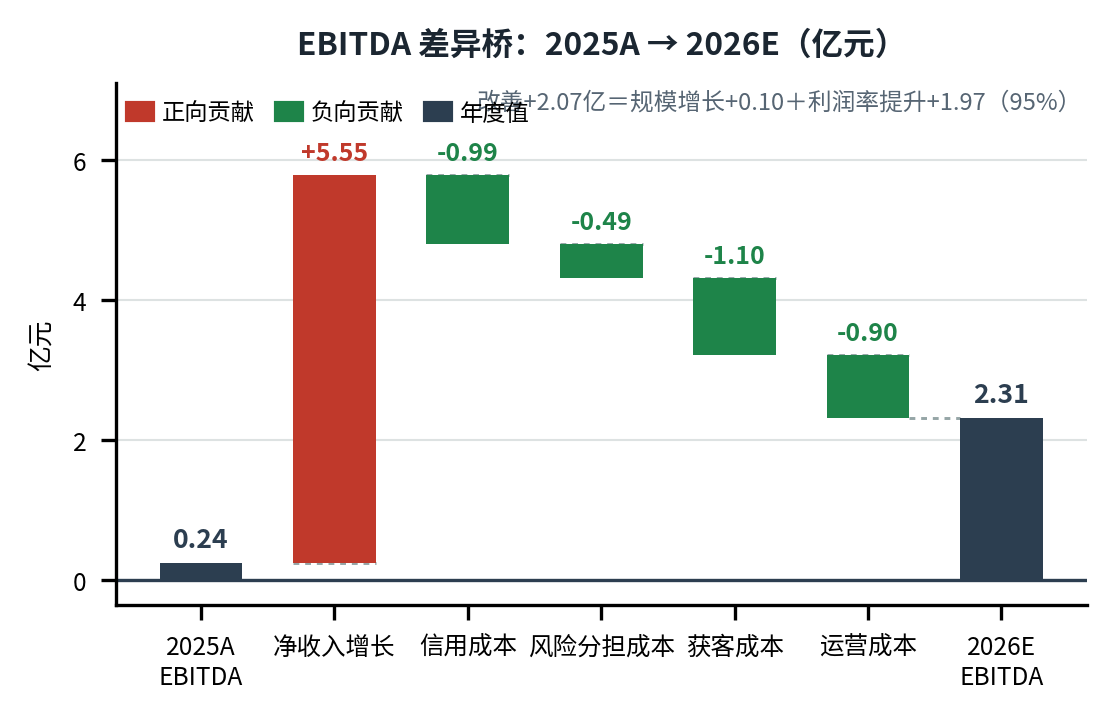

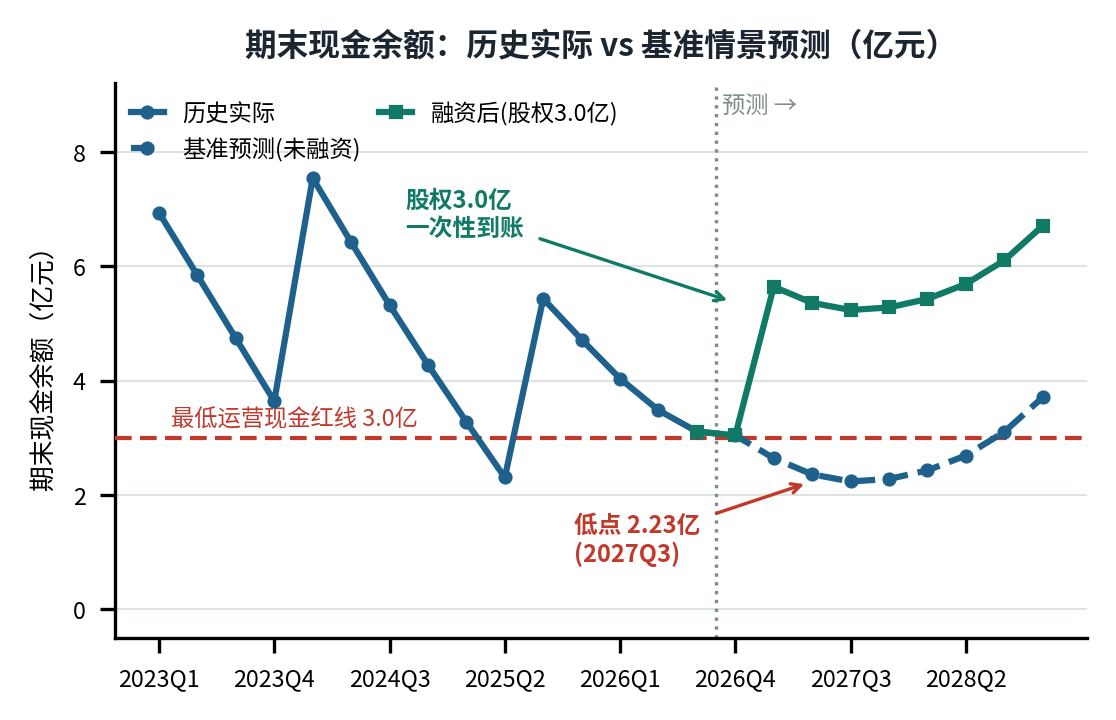

In [8]:
# -*- coding: utf-8 -*-
"""从 P4 outputs 提取确切数字，生成 MVP2 一页纸所需图表。
印刷尺度：图宽 3.62in = 92mm，嵌入一页纸后 1:1 显示，字号即印刷磅值。"""
import json
import os
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib import font_manager

# ---- OPT-1：可移植路径（脚本位于 <项目>/code/ 时定位项目根；notebook 下 cwd 即根目录）----
try:
    _HERE = os.path.dirname(os.path.abspath(__file__))
except NameError:
    _HERE = os.path.abspath(os.getcwd())
ROOT = os.path.dirname(_HERE) if os.path.basename(_HERE) == "code" else _HERE
OUT = os.path.join(ROOT, "outputs")

# ---- OPT-1：中文字体跨平台注册（① 随附提取字体 → ② 系统字体 → ③ 字体名回退）----
def _register_cjk_font():
    """注册中文字体并返回可用字体名；全部失败时回退 DejaVu Sans（缺字形但不中断）。"""
    candidates = [
        # ① 随附字体：从系统 NotoSansCJK ttc 提取的 SC 单字体面（规避 matplotlib 不支持 ttc 的问题）
        os.path.join(_HERE, "fonts", "NotoSansCJKsc-Regular.otf"),
        os.path.join(ROOT, "fonts", "NotoSansCJKsc-Regular.otf"),
        os.path.join(_HERE, "code", "fonts", "NotoSansCJKsc-Regular.otf"),  # notebook 环境：cwd 为项目根
        os.path.join(ROOT, "code", "fonts", "NotoSansCJKsc-Regular.otf"),
        # ② 系统常见字体路径
        "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc",
        "/usr/share/fonts/opentype/noto/NotoSansSC-Regular.otf",
        "/usr/share/fonts/truetype/wqy/wqy-microhei.ttc",
        "/System/Library/Fonts/PingFang.ttc",
        "C:/Windows/Fonts/msyh.ttc",
    ]
    for p in candidates:
        if os.path.exists(p):
            try:
                font_manager.fontManager.addfont(p)
            except Exception:
                pass  # ttc 多字体面注册失败时继续尝试其他候选
    # 粗体字面（存在则注册，用于标题与关键数值的真加粗）
    bold_candidates = [
        os.path.join(_HERE, "fonts", "NotoSansCJKsc-Bold.otf"),
        os.path.join(ROOT, "fonts", "NotoSansCJKsc-Bold.otf"),
        os.path.join(_HERE, "code", "fonts", "NotoSansCJKsc-Bold.otf"),
        os.path.join(ROOT, "code", "fonts", "NotoSansCJKsc-Bold.otf"),
        "/usr/share/fonts/opentype/noto/NotoSansCJK-Bold.ttc",
        "/usr/share/fonts/truetype/wqy/wqy-microhei.ttc",
        "C:/Windows/Fonts/msyhbd.ttc",
    ]
    for p in bold_candidates:
        if os.path.exists(p):
            try:
                font_manager.fontManager.addfont(p)
            except Exception:
                pass
    have = {f.name for f in font_manager.fontManager.ttflist}
    for name in ("Noto Sans CJK SC", "Noto Sans SC", "Microsoft YaHei",
                 "PingFang SC", "WenQuanYi Micro Hei", "WenQuanYi Zen Hei"):
        if name in have:
            return name
    return "DejaVu Sans"

plt.rcParams["font.sans-serif"] = [_register_cjk_font(), "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
km = json.load(open(f"{OUT}/key_metrics.json", encoding="utf-8"))
Q_HIST = [f"{y}Q{q}" for y in (2023, 2024, 2025, 2026) for q in (1, 2, 3, 4)][:15]
Q_FC = km["quarters_fc"]
Q_ALL = Q_HIST + Q_FC

C_UP, C_DOWN = "#C0392B", "#1E8449"           # 中国市场惯例：涨红跌绿
C_ANCHOR, C_LINE, C_POST, C_RED = "#2C3E50", "#1F618D", "#117A65", "#C0392B"
GRID = dict(axis="y", color="#D5DBDB", lw=0.5, alpha=0.8)

# ============================================================
# 图1：EBITDA 差异桥瀑布图（2025A -> 2026E）
# ============================================================
bridge = km["bridge"]
labels = [b[0] for b in bridge]
kinds = [b[2] for b in bridge]
short = {"2025A EBITDA": "2025A\nEBITDA", "2026E EBITDA": "2026E\nEBITDA"}

fig, ax = plt.subplots(figsize=(3.62, 2.3), dpi=300)
cum = 0.0
for i, (lb, v, kd) in enumerate(bridge):
    if kd == "anchor":
        ax.bar(i, v, width=0.62, color=C_ANCHOR, zorder=3)
        ax.text(i, v + 0.14, f"{v:.2f}", ha="center", va="bottom",
                fontsize=6.4, fontweight="bold", color=C_ANCHOR)
        if i > 0:
            ax.plot([i - 1 + 0.31, i - 0.31], [cum, cum], color="#95A5A6", lw=0.7,
                    ls=(0, (2, 2)), zorder=2)
        cum = v
    else:
        bottom = cum if v >= 0 else cum + v
        color = C_UP if v >= 0 else C_DOWN
        ax.bar(i, abs(v), bottom=bottom, width=0.62, color=color, zorder=3)
        sign_y = cum + v + 0.14 if v >= 0 else cum + 0.14
        ax.text(i, sign_y, f"{v:+.2f}", ha="center", va="bottom",
                fontsize=6.0, fontweight="bold", color=color)
        ax.plot([i - 0.31, i + 0.31], [cum, cum], color="#95A5A6", lw=0.7,
                ls=(0, (2, 2)), zorder=2)
        cum += v

ax.axhline(0, color="#2C3E50", lw=0.8)
ax.set_xticks(range(len(bridge)))
ax.set_xticklabels([short.get(lb, lb) for lb in labels], fontsize=5.9)
ax.set_ylim(-0.35, 7.1)
ax.set_yticks([0, 2, 4, 6])
ax.tick_params(axis="y", labelsize=5.9)
ax.set_ylabel("亿元", fontsize=6.2)
ax.set_title("EBITDA 差异桥：2025A → 2026E（亿元）",
             fontsize=7.6, fontweight="bold", color="#1B2631", pad=7)
ax.text(0.995, 0.985,
        f"改善+{km['eff_split']['total']:.2f}亿＝规模增长+{km['eff_split']['from_growth']:.2f}＋利润率提升+{km['eff_split']['from_margin']:.2f}（95%）",
        transform=ax.transAxes, ha="right", va="top", fontsize=5.7, color="#566573")
ax.grid(**GRID, zorder=0)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=C_UP, label="正向贡献"), Patch(color=C_DOWN, label="负向贡献"),
                   Patch(color=C_ANCHOR, label="年度值")],
          loc="upper left", fontsize=5.6, frameon=False, ncol=3,
          bbox_to_anchor=(-0.01, 1.005), handlelength=1.1, columnspacing=0.9, handletextpad=0.4)
plt.tight_layout(pad=0.35)
plt.savefig(f"{OUT}/fig1_ebitda_bridge.png", bbox_inches="tight", facecolor="white")
plt.close()

# ============================================================
# 图2：现金流折线图（历史实际 + 基准预测 + 融资后）
# ============================================================
cash_h, cash_b, cash_p = km["cash_hist"], km["cash_base"], km["cash_base_post"]
n_h, n_f = len(cash_h), len(cash_b)
x_h = np.arange(n_h)
x_f = np.arange(n_h - 1, n_h + n_f)

fig, ax = plt.subplots(figsize=(3.62, 2.3), dpi=300)
ax.plot(x_h, cash_h, color=C_LINE, lw=1.5, marker="o", ms=2.4, zorder=4, label="历史实际")
ax.plot(x_f, np.concatenate([[cash_h[-1]], cash_b]), color=C_LINE, lw=1.5, ls="--",
        marker="o", ms=2.4, zorder=4, label="基准预测(未融资)")
ax.plot(x_f, np.concatenate([[cash_h[-1]], cash_p]), color=C_POST, lw=1.5,
        marker="s", ms=2.2, zorder=4, label="融资后(股权3.0亿)")
ax.axhline(km["min_cash"], color=C_RED, lw=1.0, ls=(0, (4, 2)), zorder=3)
ax.text(0.3, km["min_cash"] + 0.14, f"最低运营现金红线 {km['min_cash']:.1f}亿",
        fontsize=5.6, color=C_RED, va="bottom")

tr = int(np.argmin(cash_b))
tr_i = n_h - 1 + tr
ax.annotate(f"低点 {cash_b[tr]:.2f}亿\n({Q_FC[tr]})", xy=(tr_i, cash_b[tr]),
            xytext=(tr_i - 6.2, cash_b[tr] - 0.55), fontsize=5.7, color=C_RED,
            fontweight="bold", va="top",
            arrowprops=dict(arrowstyle="->", color=C_RED, lw=0.8))
ax.annotate("股权3.0亿\n一次性到账", xy=(n_h, cash_p[1] - 0.28),
            xytext=(n_h - 8.6, 6.55), fontsize=5.7, color=C_POST, fontweight="bold",
            arrowprops=dict(arrowstyle="->", color=C_POST, lw=0.8))

ticks = list(range(0, n_h + n_f, 3))
ax.set_xticks(ticks)
ax.set_xticklabels([Q_ALL[i] for i in ticks], fontsize=5.6)
ax.tick_params(axis="y", labelsize=5.6)
ax.set_ylim(-0.5, 9.2)
ax.set_ylabel("期末现金余额（亿元）", fontsize=6.2)
ax.set_title("期末现金余额：历史实际 vs 基准情景预测（亿元）",
             fontsize=7.6, fontweight="bold", color="#1B2631", pad=7)
ax.grid(**GRID, zorder=0)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.axvline(n_h - 0.5, color="#7F8C8D", lw=0.8, ls=":")
ax.text(n_h - 0.35, 8.7, "预测 →", fontsize=5.6, color="#7F8C8D")
ax.legend(loc="upper left", fontsize=5.6, frameon=False, ncol=2,
          bbox_to_anchor=(-0.005, 1.005), handlelength=1.4, columnspacing=0.8)
plt.tight_layout(pad=0.35)
plt.savefig(f"{OUT}/fig2_cashflow.png", bbox_inches="tight", facecolor="white")
plt.close()
print("charts done (print scale)")


# 在 notebook 内联展示生成的图表
from IPython.display import Image, display
display(Image(filename=f"{OUT}/fig1_ebitda_bridge.png"))
display(Image(filename=f"{OUT}/fig2_cashflow.png"))
